# 📈 Notebook 5: Hồi quy Tuyến tính (Linear Regression)
## Đề tài: Customer Churn Prediction – Phần bổ sung: Hồi quy tuyến tính

**Bốn mục tiêu của notebook**
1. **Xây dựng và đọc mô hình:** hồi quy tuyến tính, diễn giải từng hệ số theo ngữ cảnh bài toán.
2. **Đánh giá mô hình trung thực:** thước đo phù hợp, luôn chấm trên dữ liệu mô hình chưa từng thấy.
3. **Chẩn đoán mô hình:** kiểm tra bốn giả định cơ bản (LINE) và nhận biết khi nào **không nên** dùng.
4. **Kiểm soát overfitting:** tách dữ liệu, kiểm định chéo, điều chuẩn (Ridge/Lasso).

> **Vì sao dự đoán `MonthlyCharges` mà không phải `Churn`?** Hồi quy tuyến tính dành cho biến **liên tục**. `Churn` là biến 0/1 nên đồ án dùng Logistic Regression; ở mục 6 sẽ chứng minh bằng số liệu vì sao hồi quy tuyến tính không hợp với Churn.

**Cấu trúc:** (0) dữ liệu → (1) mô hình & hệ số → (2) đánh giá trung thực → (3) chẩn đoán → (4) overfitting & điều chuẩn → (5) khi nào KHÔNG dùng (Churn) → (6) kết luận.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..') if os.path.exists('../src') else os.path.abspath('.'))
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
from IPython.display import Image, display

from src.config import FIGURES_DIR
from src.regression import (load_regression_data, split_regression_data, fit_ols, coefficient_table,
                            honest_evaluation, diagnostics_report, vif_with_numservices, plot_diagnostics,
                            linear_probability_demo, plot_lpm_misuse, overfitting_demo, train_test_gap_by_n,
                            plot_overfitting, regularization_full, plot_regularization_paths, REG_EXCLUDED)

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

---
## 0. Dữ liệu và cách chia

- **Biến mục tiêu:** `MonthlyCharges` (cước hàng tháng, USD).
- **Biến bị loại có chủ ý:** `TotalCharges`, `AvgChargePerMonth` (tính từ chính `MonthlyCharges` → **rò rỉ dữ liệu**), `NumServices` (= tổng các cột dịch vụ → **đa cộng tuyến hoàn hảo**), `Churn` (không có khi lập hóa đơn).
- **Chia dữ liệu:** đúng `config.py` (80/20, `random_state=42`). Tập test **chỉ dùng để chấm điểm cuối**.

In [2]:
df, X, y = load_regression_data()
X_train, X_test, y_train, y_test = split_regression_data(X, y)
print('Biến bị loại:', REG_EXCLUDED)
print(f'Số biến đầu vào: {X.shape[1]} | Train: {len(X_train):,} | Test: {len(X_test):,}')
print(f'MonthlyCharges: min={y.min()}, max={y.max()}, trung bình={y.mean():.2f}, độ lệch chuẩn={y.std():.2f}')

Biến bị loại: ['MonthlyCharges', 'TotalCharges', 'AvgChargePerMonth', 'NumServices', 'Churn']
Số biến đầu vào: 21 | Train: 5,634 | Test: 1,409
MonthlyCharges: min=18.25, max=118.75, trung bình=64.76, độ lệch chuẩn=30.09


---
## 1. Xây dựng và đọc mô hình

$$\hat y=\beta_0+\beta_1x_1+\dots+\beta_px_p,\qquad \hat\beta=\arg\min_\beta\sum(y_i-\hat y_i)^2$$

**Cách đọc hệ số $\beta_j$:** *khi các biến khác giữ nguyên, tăng $x_j$ thêm 1 đơn vị thì kỳ vọng $y$ đổi $\beta_j$ đơn vị.* Với biến 0/1, $\beta_j$ là **chênh lệch giữa nhóm có và không có**; với biến one-hot là chênh lệch **so với nhóm gốc** bị bỏ (DSL, hợp đồng theo tháng, chuyển khoản tự động). Hệ số chỉ nói về **tương quan có điều kiện**, chưa chứng minh nhân quả.

In [3]:
ols = fit_ols(X_train, y_train)
coef = coefficient_table(ols)
display(coef.round(4))

,coef,ci_low,ci_high,p_value,significant
const,24.9675,24.8414,25.0935,0.0000,True
gender,0.0170,-0.0363,0.0704,0.5315,False
SeniorCitizen,0.0124,-0.0654,0.0902,0.7541,False
Partner,0.0103,-0.0541,0.0747,0.7548,False
Dependents,-0.0173,-0.0857,0.0511,0.6203,False
tenure,-0.0002,-0.0020,0.0016,0.8141,False
PhoneService,20.0346,19.9300,20.1393,0.0000,True
MultipleLines,5.0185,4.9539,5.0830,0.0000,True
OnlineSecurity,5.0551,4.9852,5.1249,0.0000,True
OnlineBackup,4.9867,4.9211,5.0523,0.0000,True


**Nhận xét**
- Hệ số khớp **bảng giá dịch vụ**: có điện thoại **+20,03 USD**; mỗi dịch vụ bảo mật/hỗ trợ **≈ +5 USD**; Streaming TV/Movies **≈ +10 USD**; Fiber cao hơn DSL **≈ +24,95 USD**; không dùng internet rẻ hơn DSL **≈ 25 USD**.
- Hằng số 24,97 là cước nền của khách DSL, không điện thoại, không dịch vụ thêm.
- Kiểm tra tay: chỉ điện thoại (không internet) = 24,97 + 20,03 − 25,02 = **19,98 USD** (khách thật trung bình ≈ 21,08 USD).
- `tenure`, nhân khẩu học, `Contract`, `PaymentMethod`, `PaperlessBilling` đều **không có ý nghĩa** (p từ 0,43 đến 0,99; khoảng tin cậy chứa 0). Chúng không ảnh hưởng **cước tháng**, nhưng vẫn là yếu tố mạnh của **Churn**: hệ số phụ thuộc vào biến mục tiêu đã chọn.
- p-value nhỏ chỉ cho biết hệ số khác 0 chắc chắn đến đâu; **độ lớn ảnh hưởng** đọc ở chính hệ số và khoảng tin cậy.

---
## 2. Đánh giá mô hình trung thực

**Nguyên tắc:** điểm số chỉ có giá trị khi tính trên dữ liệu **chưa từng thấy**. Ba lớp bảo vệ: (1) **baseline** luôn đoán trung bình; (2) **tập test giữ kín**; (3) **cross-validation 5-fold** trên train. Thước đo: **RMSE** và **MAE** (cùng đơn vị USD) và **R²** (phần phương sai giải thích được so với baseline).

$$R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2},\quad RMSE=\sqrt{\tfrac1n\sum(y_i-\hat y_i)^2},\quad MAE=\tfrac1n\sum|y_i-\hat y_i|$$

In [4]:
ev = honest_evaluation(X_train, X_test, y_train, y_test)
display(ev.round(4))

,R2,RMSE,MAE,R2_std_CV
Baseline (đoán trung bình train) - test,-0.0003,30.0938,26.0328,NaN
OLS - train,0.9989,1.0182,0.7797,NaN
OLS - test (chưa từng thấy),0.9988,1.0513,0.7893,NaN
OLS - CV 5-fold (trung bình),0.9988,1.0219,NaN,0.0001


**Nhận xét**
- Baseline: R² ≈ 0, sai số trung bình 26 USD (đúng bằng độ phân tán của cước). Mô hình hạ RMSE từ **30,09 xuống 1,05 USD** (khoảng 29 lần).
- Train và test gần như bằng nhau (RMSE 1,02 so với 1,05), 5 fold gần như giống nhau (R² ≈ 0,9988 ± 0,0001) → **mô hình tổng quát hóa tốt**.
- ⚠️ **R² ≈ 0,999 là do bản chất dữ liệu**: cước tháng gần như là phép cộng bảng giá, rất dễ dự đoán. Đây là bài minh họa kỹ thuật tốt, không phải bằng chứng mô hình mạnh trong tình huống khó. Đã loại `TotalCharges`/`AvgChargePerMonth` để không rò rỉ.

---
## 3. Chẩn đoán mô hình: bốn giả định (LINE)

| Giả định | Kiểm tra | Nếu vi phạm |
|:--|:--|:--|
| **L**inearity (tuyến tính) | Residuals vs Fitted; RESET | thêm bậc cao, log, hoặc mô hình phi tuyến |
| **I**ndependence (độc lập) | cách thu dữ liệu; Durbin-Watson ≈ 2 | mô hình chuỗi thời gian / phân cụm |
| **N**ormality (phần dư chuẩn) | Q-Q plot; Jarque-Bera, Shapiro | mẫu lớn thì ảnh hưởng nhỏ |
| **E**qual variance (phương sai không đổi) | Scale-Location; Breusch-Pagan | sai số chuẩn vững (HC3), biến đổi y |

Ngoài ra kiểm tra **đa cộng tuyến (VIF)** và **điểm ảnh hưởng (Cook's distance)**. Bốn giả định đảm bảo **suy luận** (p-value, khoảng tin cậy) đáng tin, **không** phải để dự đoán tốt. Với mẫu lớn, kiểm định gần như luôn cho p rất nhỏ, nên phải xem **biểu đồ** và **độ lớn của vi phạm**.

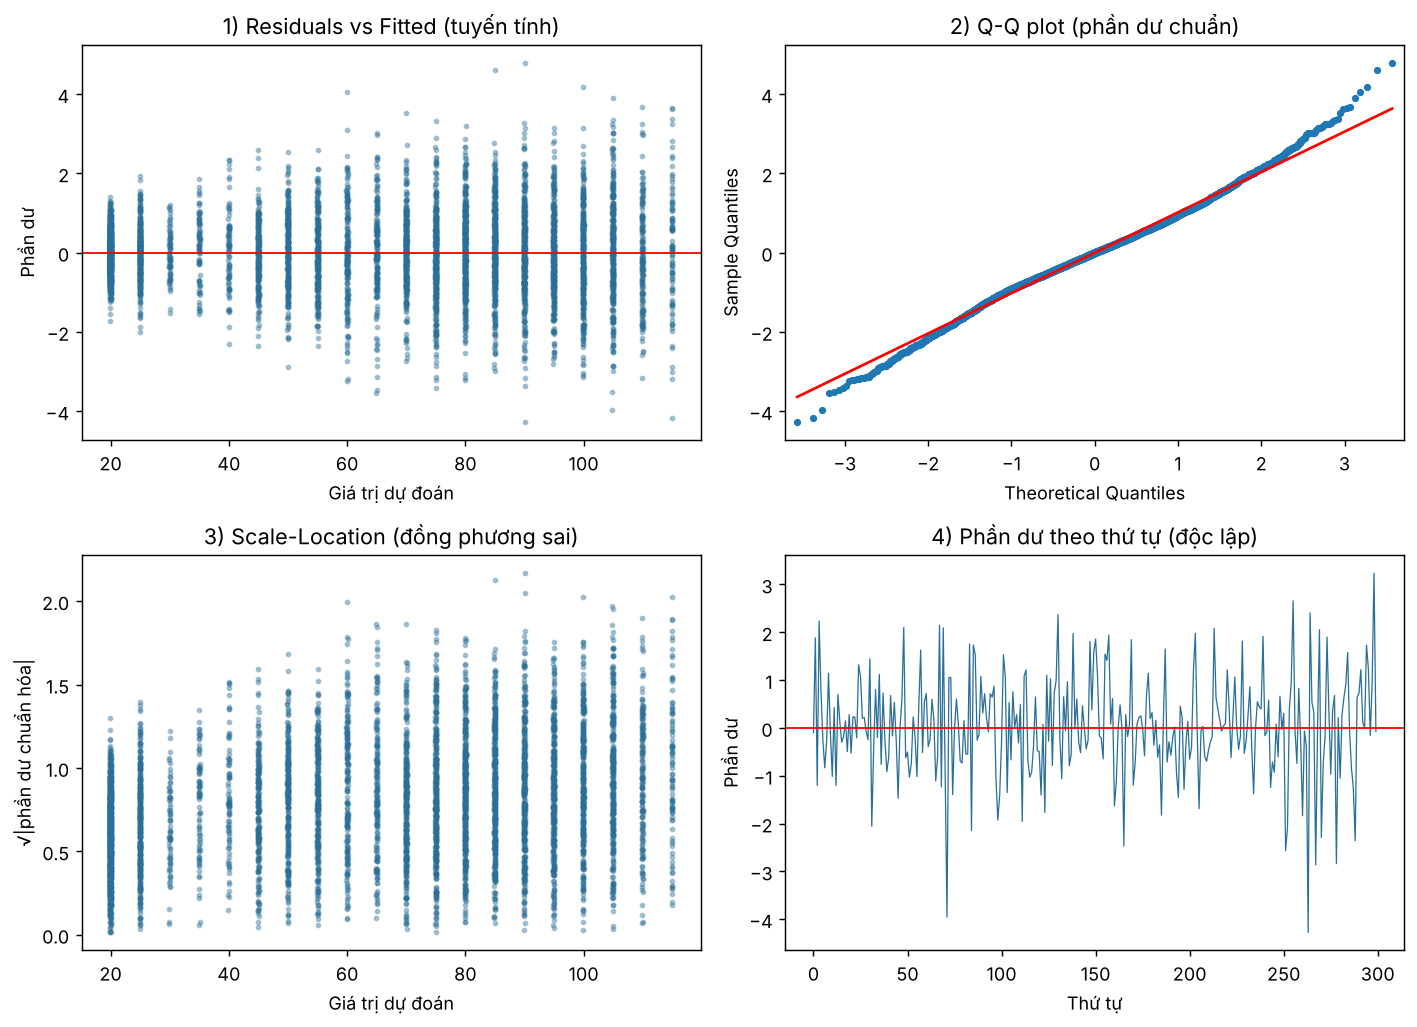

,Kiểm tra,Giá trị
0,Tuyến tính (RESET),"F=0.11, p=0.74"
1,Độc lập (Durbin-Watson),2.03
2,Chuẩn (Jarque-Bera),p=3.4e-38; lệch=0.02; nhọn=3.86
3,Chuẩn (Shapiro-Wilk),"W=0.994, p=2.0e-11"
4,Phương sai (Breusch-Pagan),"LM=575, p=2.7e-108"
5,Đa cộng tuyến (VIF lớn nhất),2.74 (tenure)
6,Điểm ảnh hưởng (Cook lớn nhất),0.0042


Độ lệch chuẩn phần dư theo nhóm giá dự đoán (thấp/giữa/cao): {'thấp': 0.666, 'giữa': 1.076, 'cao': 1.229}


VIF lớn nhất nếu thêm NumServices (tổng các cột dịch vụ): 1.00e+15


In [5]:
diag = diagnostics_report(ols)
plot_diagnostics(ols)
display(Image(filename=str(FIGURES_DIR / '13_reg_diagnostics.png')))
summary = pd.DataFrame({
    'Kiểm tra': ['Tuyến tính (RESET)', 'Độc lập (Durbin-Watson)', 'Chuẩn (Jarque-Bera)', 'Chuẩn (Shapiro-Wilk)',
                 'Phương sai (Breusch-Pagan)', 'Đa cộng tuyến (VIF lớn nhất)', "Điểm ảnh hưởng (Cook lớn nhất)"],
    'Giá trị': [f"F={diag['linearity_RESET']['F']:.2f}, p={diag['linearity_RESET']['p']:.2f}",
                f"{diag['independence_DW']:.2f}",
                f"p={diag['normality_JB']['p']:.1e}; lệch={diag['normality_JB']['skew']:.2f}; nhọn={diag['normality_JB']['kurtosis']:.2f}",
                f"W={diag['normality_Shapiro']['W']:.3f}, p={diag['normality_Shapiro']['p']:.1e}",
                f"LM={diag['homoscedasticity_BP']['LM']:.0f}, p={diag['homoscedasticity_BP']['p']:.1e}",
                f"{max(diag['vif'].values()):.2f} ({max(diag['vif'], key=diag['vif'].get)})",
                f"{diag['cooks_distance_max']:.4f}"]})
display(summary)
print('Độ lệch chuẩn phần dư theo nhóm giá dự đoán (thấp/giữa/cao):', diag['resid_sd_by_fitted_tercile'])
print(f"VIF lớn nhất nếu thêm NumServices (tổng các cột dịch vụ): {vif_with_numservices(X_train, df):.2e}")

**Nhận xét**
- **Tuyến tính** đạt (RESET p = 0,74, phần dư không cong). **Độc lập**: DW = 2,03 nhưng Telco là dữ liệu **cắt ngang** (mỗi dòng một khách), thứ tự dòng không có ý nghĩa; độc lập chủ yếu dựa vào cách thu thập.
- **Chuẩn** và **phương sai** vi phạm về **thống kê** (p rất nhỏ), nhưng **không đáng kể trong thực tế**: lệch ≈ 0,02, độ nhọn 3,86; độ lệch chuẩn phần dư tăng 0,67 → 1,08 → 1,23 USD theo mức giá (trên thang 30 USD). Nên báo cáo thêm **sai số chuẩn vững (HC3)**.
- **VIF** lớn nhất 2,74 (an toàn). Thêm `NumServices` làm VIF vọt lên ~10¹⁵ → hệ số không còn xác định duy nhất → phải loại.
- **Cook's distance** lớn nhất 0,0042 ≪ 1: không dòng nào chi phối mô hình, **nhất quán với kết luận phần Outlier** (giữ nguyên toàn bộ 7.043 khách).

---
## 4. Kiểm soát overfitting: tách dữ liệu, cross-validation, điều chuẩn

| Công cụ | Trả lời câu hỏi | Ghi chú |
|:--|:--|:--|
| **Train/Test split** | Điểm trên dữ liệu lạ là bao nhiêu? | test chỉ dùng một lần |
| **K-fold CV** | Điểm ổn định hay may rủi? chọn tham số? | tiền xử lý phải làm **trong** từng fold |
| **Ridge (L2)** | Làm sao bớt nhạy với nhiễu? | **co** hệ số về gần 0 |
| **Lasso (L1)** | Biến nào thật sự cần? | **ép** một số hệ số về đúng 0 |

$$\text{Ridge: }\min\sum(y_i-\hat y_i)^2+\alpha\sum\beta_j^2\qquad\text{Lasso: }\min\sum(y_i-\hat y_i)^2+\alpha\sum|\beta_j|$$

> Liên hệ đồ án: `LogisticRegression(C=1.0)` trong `modeling.py` đã là điều chuẩn L2 (C nhỏ hơn = phạt mạnh hơn); `max_depth`, `min_samples_leaf` là điều chuẩn của cây; `StratifiedKFold(5)` là CV có phân tầng.

### 4.1. Thí nghiệm gây overfitting có chủ ý
Với 5.634 dòng, OLS **không** overfitting. Để thấy hiện tượng, lấy ngẫu nhiên **150 dòng** train và mở rộng 21 biến thành **252 đặc trưng bậc 2** (nhiều đặc trưng hơn số mẫu), chấm trên cùng tập test.

,R2 train,R2 CV 5-fold,R2 test,RMSE test
Mô hình,,,,
OLS bậc 1,0.9989,0.9984,0.9986,1.1147
OLS bậc 2,1.0000,0.9770,0.9719,5.0444
Ridge bậc 2 (α theo CV),0.9999,0.9883,0.9921,2.6783
Lasso bậc 2 (α theo CV),0.9991,0.9977,0.9984,1.2016


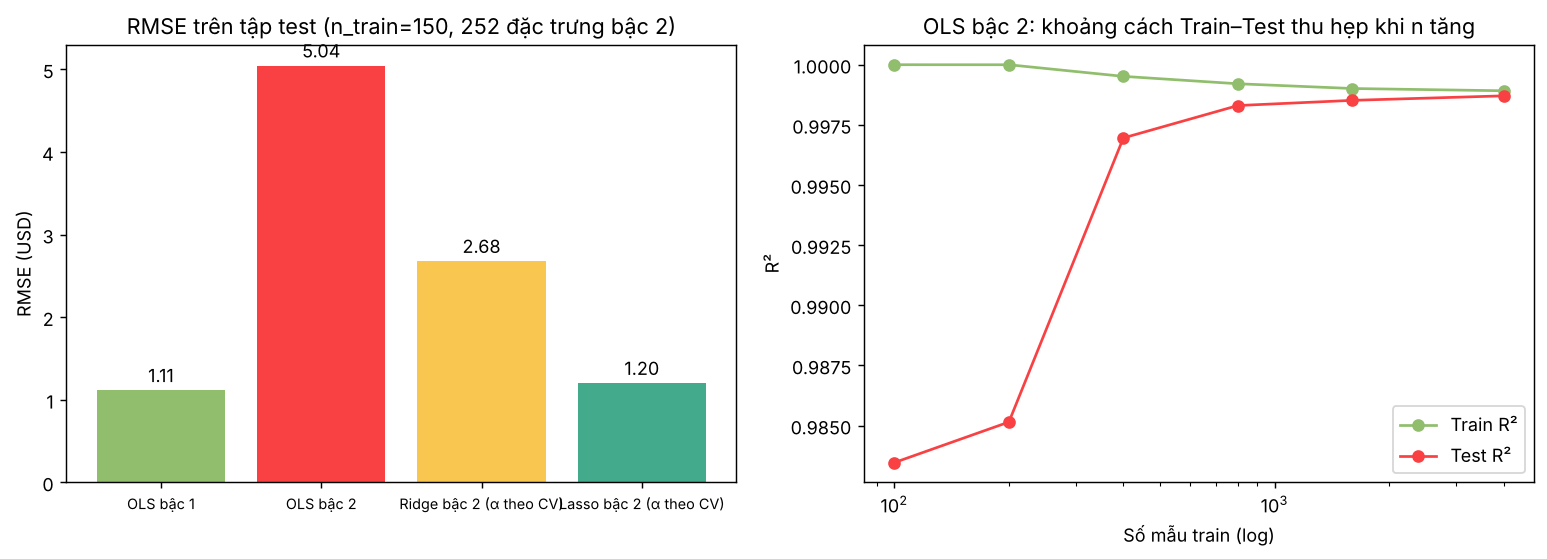

,R2 train,R2 test
n_train,,
100,1.0000,0.9835
200,1.0000,0.9851
400,0.9995,0.9970
800,0.9992,0.9983
1600,0.9990,0.9985
4000,0.9989,0.9987


In [6]:
demo = overfitting_demo(X_train, y_train, X_test, y_test)
gap = train_test_gap_by_n(X_train, y_train, X_test, y_test)
plot_overfitting(demo, gap)
display(demo.round(4))
display(Image(filename=str(FIGURES_DIR / '14_reg_overfitting.png')))
display(gap.round(4))

**Nhận xét**
- **Train là thước đo vô dụng:** OLS bậc 2 có R² train ≈ 1,0000 nhưng RMSE test tăng **gấp 4,5 lần** (1,11 → 5,04 USD). R² gần 1 che mất sai lệch; RMSE mới thấy rõ.
- **CV báo trước đúng:** R² CV 0,9770 sát R² test 0,9719, trong khi train nói 1,0000 → dùng CV để chọn mô hình mà không cần chạm test.
- **Điều chuẩn cứu được:** Ridge giảm RMSE test còn 2,68; Lasso còn 1,20 (gần mức đúng 1,11). Quan hệ thật là tuyến tính nên thêm độ phức tạp chỉ làm tệ đi.
- **Thêm dữ liệu cũng cứu được:** khoảng cách train–test co từ 1,0000 vs 0,9835 (n=100) xuống 0,9989 vs 0,9987 (n=4.000).

### 4.2. Ridge và Lasso trên toàn bộ train
Biến đã chuẩn hóa (scaler fit trên **train**), α chọn bằng CV 5-fold.

,alpha,RMSE test,Số hệ số = 0
OLS,NaN,1.0513,0
Ridge,0.3728,1.0513,0
Lasso,0.0115,1.0510,11


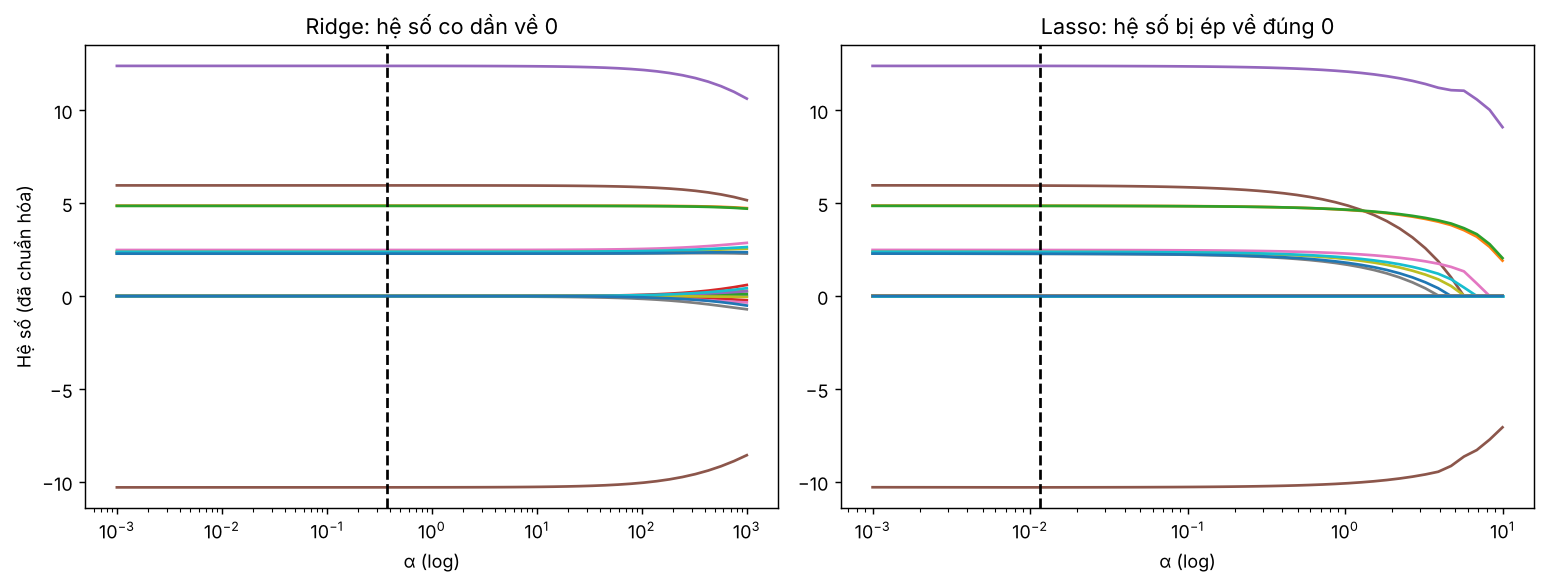

Lasso ép về 0: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PaperlessBilling', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [7]:
table, lasso_coef, paths = regularization_full(X_train, X_test, y_train, y_test)
plot_regularization_paths(paths)
display(table.round(4))
display(Image(filename=str(FIGURES_DIR / '15_reg_regularization_path.png')))
print('Lasso ép về 0:', list(lasso_coef[lasso_coef == 0].index))

**Nhận xét**
- Trên dữ liệu đủ lớn, điều chuẩn **không cải thiện điểm** (RMSE 1,0513 so với 1,0510): mô hình vốn không overfitting. Điều chuẩn là **bảo hiểm** khi dữ liệu ít hoặc nhiều biến.
- Lasso ép về 0 đúng **11 biến** mà OLS ở mục 1 đã báo **không có ý nghĩa** (gender, SeniorCitizen, Partner, Dependents, tenure, PaperlessBilling, 2 cột Contract, 3 cột PaymentMethod). Hai phương pháp độc lập cùng chỉ về một đáp án.
- Phải **chuẩn hóa** trước khi phạt (nếu không biến có thang lớn bị phạt khác biến 0/1) và scaler phải fit trên train.

---
## 5. Khi nào KHÔNG dùng hồi quy tuyến tính: ví dụ dự đoán Churn

Thử dùng OLS để dự đoán `Churn` (0/1) trên cùng cấu hình chia (80/20, `random_state=42`, có phân tầng theo Churn).

,Kết quả
n_test,1.409000e+03
pred_below_0,2.340000e+02
pred_above_1,0.000000e+00
pred_min,-2.350494e-01
pred_max,7.848841e-01
R2_test,2.604796e-01
AUC_linear,8.337157e-01
AUC_logistic,8.388824e-01
BP_p,2.457727e-225
Shapiro_p,2.531038e-31


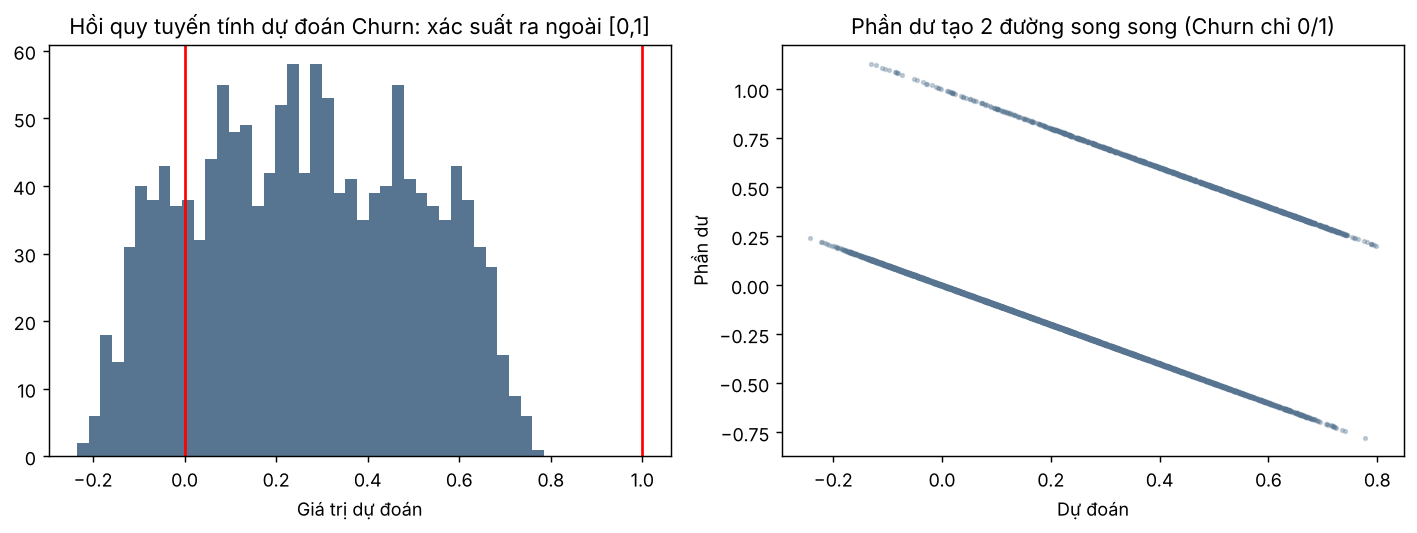

234 / 1409 khách (16.6%) có 'xác suất' < 0


In [8]:
info, p, lpm_ols = linear_probability_demo(df)
plot_lpm_misuse(p, lpm_ols)
display(pd.Series(info).to_frame('Kết quả'))
display(Image(filename=str(FIGURES_DIR / '16_reg_lpm_misuse.png')))
print(f"{info['pred_below_0']} / {info['n_test']} khách ({info['pred_below_0']/info['n_test']:.1%}) có 'xác suất' < 0")

**Nhận xét**
- **16,6%** dự đoán là xác suất **âm** (thấp nhất −0,235) → không dùng được để đặt ngưỡng hay tính chi phí chăm sóc.
- R² test chỉ **0,26**; phần dư xếp thành **hai đường song song** (vì Churn chỉ có hai giá trị) nên không thể chuẩn; Breusch-Pagan p ≈ 10⁻²²⁵ (phương sai $p(1-p)$ thay đổi theo mức dự đoán).
- **Cân bằng:** về **xếp hạng** khách, OLS gần bằng Logistic (AUC 0,834 so với 0,839). Cái sai là **ý nghĩa của con số** (xác suất, sai số chuẩn, p-value). Muốn xác suất churn hợp lệ phải dùng **Logistic Regression** – đúng như lựa chọn của đồ án.
- Các tình huống khác không nên dùng: phần dư cong rõ; dữ liệu chuỗi thời gian/đo lặp (phần dư tự tương quan); biến đầu vào là tổng của nhau; có điểm ảnh hưởng lớn (Cook ≈ 1); dự đoán ngoài vùng dữ liệu (extrapolation).

---
## 6. Kết luận

| Mục tiêu | Kết quả trên Telco |
|:--|:--|
| 1. Xây dựng & đọc mô hình | Hệ số tái hiện bảng giá (điện thoại +20, add-on +5, streaming +10, Fiber +25, không internet −25 USD) |
| 2. Đánh giá trung thực | Test R² 0,9988, RMSE 1,05 USD so với baseline 30,09 USD; train ≈ test ≈ CV |
| 3. Chẩn đoán | Tuyến tính, độc lập đạt; phương sai, độ chuẩn vi phạm thống kê nhưng không đáng kể (~1 USD); VIF ≤ 2,74; Cook ≤ 0,0042 |
| 4. Overfitting | Gây có chủ ý (150 mẫu, 252 đặc trưng): train ≈ 1,0 nhưng RMSE test ×4,5; CV báo đúng; Lasso/Ridge cứu; trên toàn dữ liệu điều chuẩn không đổi điểm và Lasso khớp OLS ở 11 biến thừa |
| Không nên dùng | Hồi quy tuyến tính cho Churn: 16,6% xác suất âm → dùng Logistic Regression |

**Giới hạn cần nói thẳng**
- R² ≈ 0,999 do bản chất bảng giá, không phải bằng chứng mô hình mạnh trong bài toán khó.
- Overfitting ở 4.1 là **cố ý gây ra** để minh họa, không phải lỗi pipeline.
- Chỉ **một** lần chia train/test (`random_state=42`) và một mẫu con 150 dòng; chưa lặp nhiều seed như phần Outlier.
- Phần Churn dùng chia có phân tầng và Logistic Regression bản đơn giản (không `class_weight`), nên AUC có thể lệch nhẹ so với báo cáo chính.

**Chạy lại:** `python run_regression.py` (kết quả ở `reports/regression_analysis/`, hình `13`–`16` ở `reports/figures/`). Mã nguồn: `src/regression.py`.